# 2. An office building with EnergyPlus

A complete study on a real model: an office building (EnergyPlus 9.6) in Larnaca. Four design parameters,
three energy objectives, adaptive sampling, three surrogate models compared on held-out simulations,
multi-objective optimization, and a check of the selected design with a real simulation.

Everything below was executed against EnergyPlus 9.6 with a deliberately small budget (32 simulations, about 8
minutes on 4 cores) so that the tutorial can be rebuilt; a real study would use more. The model and weather file
are in `examples/models/` of the repository.

:::{note}
You need an EnergyPlus **9.6** installation to run it yourself (`python tools/install_eplus.py 9.6`), or
`eplus=...` pointing at any version together with `auto_upgrade=True`.
:::

In [1]:
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)
from pathlib import Path

from bdopt import (CategoryParameter, EnergyPlusEvaluator, FieldSelector, Parameter, Problem,
                   RangeParameter, load_idf, viz)

MODELS = Path("../../examples/models")        # relative to this notebook

## The model

{func}`~bdopt.load_idf` reads the file without needing EnergyPlus; `version` is what the file says it was written
for.

In [2]:
building = load_idf(MODELS / "Office_IDF.idf")
epw = MODELS / "Larnaca_Larnax_Airp_-hour.epw"
print(building, "|", len(building.by_class("Lights")), "lighting objects,",
      len(building.by_class("Zone")), "zones")

IDF(513 objects, version=9.6.0) | 10 lighting objects, 10 zones


## The design space

Each {class}`~bdopt.Parameter` has a selector (where in the IDF) and a range. `object_name="*"` writes the value
into every object of the class.

In [3]:
parameters = [
    Parameter(FieldSelector("Material", "_InsulationEX_.01", "Thickness"),
              RangeParameter(0.1, 0.5), name="Wall insulation [m]"),
    Parameter(FieldSelector("Material", "_InsulationEX_Roof_.01", "Thickness"),
              RangeParameter(0.1, 0.8), name="Roof insulation [m]"),
    Parameter(FieldSelector("Lights", "*", "Watts per Zone Floor Area"),
              RangeParameter(5, 20), name="Lighting [W/m2]"),
    Parameter(FieldSelector("ZoneVentilation:DesignFlowRate", "*", "Air Changes per Hour"),
              RangeParameter(0, 6), name="Ventilation [ACH]"),
]
objectives = ["Electricity:Facility", "DistrictHeating:Facility", "DistrictCooling:Facility"]
problem = Problem(parameters, objectives)
problem

Problem(4 parameters, objectives=['Electricity:Facility', 'DistrictHeating:Facility', 'DistrictCooling:Facility'])

## The evaluator

The EnergyPlus version is chosen to match the model; results are cached under `runs/cache`, so re-running a cell
or the whole notebook does not repeat finished simulations.

In [4]:
evaluator = EnergyPlusEvaluator(problem, building, epw, out_dir="runs", processes=4)
print(evaluator.eplus)

EnergyPlus 9.6.0 (/opt/eplus/EnergyPlus-9.6.0-f420c06a69-Linux-Ubuntu20.04-x86_64)


## Adaptive sampling

12 initial simulations, 4 held out to measure the error, then 8 iterations of 2 new simulations each.

In [5]:
from bdopt.adaptive import AdaptiveSampler

sampler = AdaptiveSampler(problem, evaluator, method="flola_voronoi", seed=0)
result = sampler.run(n_initial=12, n_test=4, max_iter=8, batch=2, tol=0.0)
print(result)
print(evaluator.stats())

[bdopt] iter   0  train=  12  evals=  16  scaled_rmse=0.0852


[bdopt] iter   1  train=  14  evals=  18  scaled_rmse=0.0844


[bdopt] iter   2  train=  16  evals=  20  scaled_rmse=0.0830


[bdopt] iter   3  train=  18  evals=  22  scaled_rmse=0.0860


[bdopt] iter   4  train=  20  evals=  24  scaled_rmse=0.0886


[bdopt] iter   5  train=  22  evals=  26  scaled_rmse=0.0858


[bdopt] iter   6  train=  24  evals=  28  scaled_rmse=0.0545


[bdopt] iter   7  train=  26  evals=  30  scaled_rmse=0.0390


[bdopt] iter   8  train=  28  evals=  32  scaled_rmse=0.0390
AdaptiveResult(28 train + 4 test points, scaled_rmse=0.0390, stop='max_iter')
{'simulations': 32, 'cache_hits': 0, 'failed': 0, 'simulation_seconds': 1005.87, 'eplus_version': '9.6.0'}


In [6]:
result.history[["iteration", "n_train", "n_evaluations", "scaled_rmse", "elapsed_s"]]

,iteration,n_train,n_evaluations,scaled_rmse,elapsed_s
0,0,12,16,0.0852,149.27
1,1,14,18,0.0844,182.92
2,2,16,20,0.0830,216.60
3,3,18,22,0.0860,252.51
4,4,20,24,0.0886,287.32
5,5,22,26,0.0858,320.14
6,6,24,28,0.0545,353.28
7,7,26,30,0.0390,386.90
8,8,28,32,0.0390,421.46


`scaled_rmse` is the error on the 4 held-out simulations, in units of the standard deviation of each
objective. It need not fall monotonically: with so few points a new simulation can temporarily make the model
worse before it makes it better. A real study would set `tol` and a larger budget.

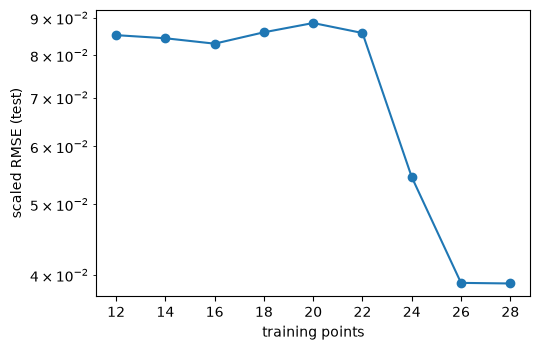

In [7]:
viz.convergence(result.history)
plt.show()

## The simulated designs

Objectives are in joules (the unit EnergyPlus reports); use `MeterReader(..., unit="kWh")` for others.

In [8]:
data = result.data
data.describe().T[["min", "mean", "max"]]

,min,mean,max
Wall insulation [m],1.0106e-01,2.7998e-01,4.9536e-01
Roof insulation [m],1.0459e-01,3.9658e-01,7.9945e-01
Lighting [W/m2],5.0279e+00,1.2679e+01,1.9864e+01
Ventilation [ACH],1.3545e-02,3.1046e+00,5.9577e+00
Electricity:Facility,1.0301e+11,1.2299e+11,1.4176e+11
DistrictHeating:Facility,1.3003e+09,2.2467e+09,3.8098e+09
DistrictCooling:Facility,1.7830e+11,1.8738e+11,1.9918e+11


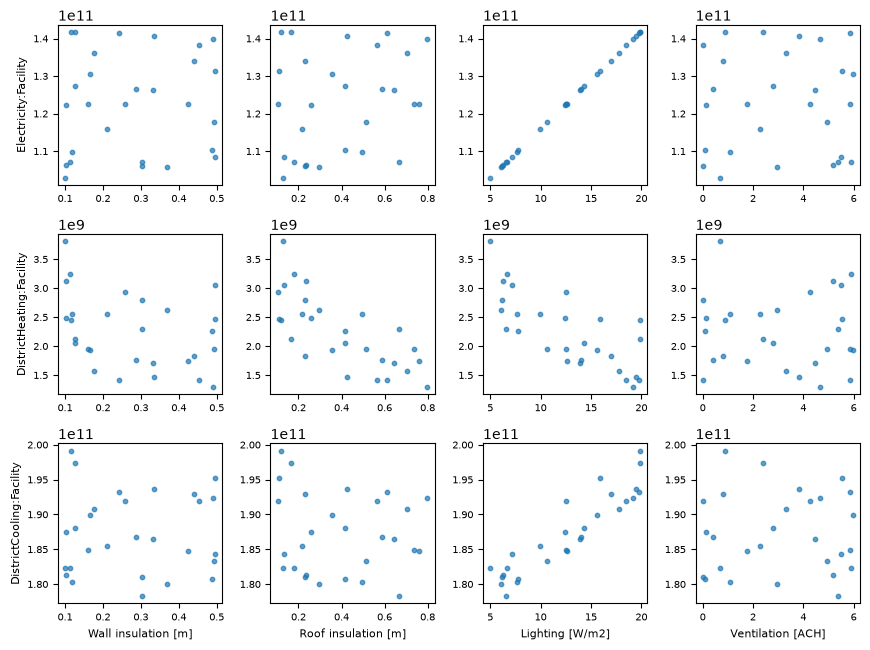

In [9]:
viz.pairplot(data, problem, size=2.2)
plt.show()

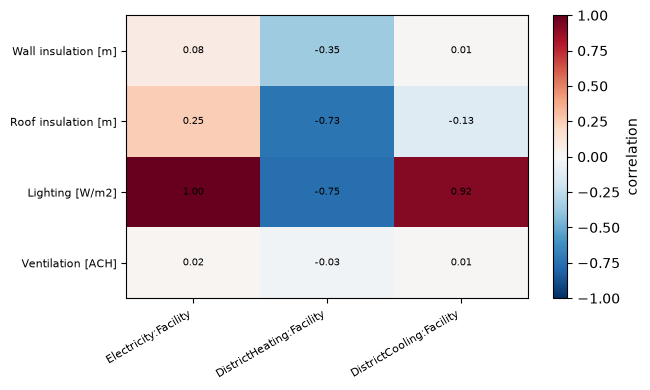

In [10]:
viz.correlation_heatmap(data, problem)
plt.show()

## Surrogate models

Three models trained on the same simulations and scored on the same held-out simulations. Inputs and outputs
are scaled inside the models, using the training data only.

In [11]:
from bdopt.surrogate import GPSurrogate, MLPSurrogate, TorchMLP

models = {
    "Gaussian process": GPSurrogate(),
    "MLP (scikit-learn)": MLPSurrogate(),
    "MLP (PyTorch, 3 nets)": TorchMLP(hidden=(32, 64, 32), n_ensemble=3),
}
scores = {}
for name, model in models.items():
    model.fit(data, problem)
    scores[name] = model.score(result.test)

summary = pd.DataFrame({name: s["rmse_pct"] for name, s in scores.items()})
summary.round(2)          # RMSE as % of the mean of the held-out values

,Gaussian process,MLP (scikit-learn),"MLP (PyTorch, 3 nets)"
Electricity:Facility,0.00,0.45,0.68
DistrictHeating:Facility,1.45,6.57,6.26
DistrictCooling:Facility,0.05,0.30,0.29


With only 12 training points the models are rough; the point here is the workflow. The table says which
model to trust on this data.

selected: Gaussian process


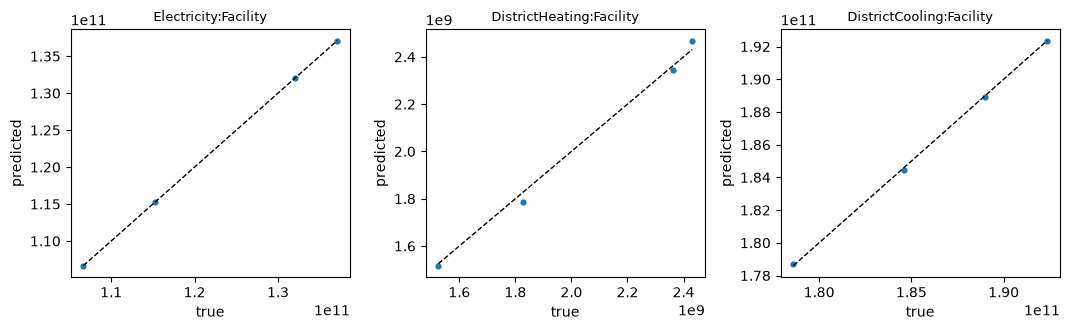

In [12]:
best_name = summary.mean().idxmin()
surrogate = models[best_name]
print("selected:", best_name)
viz.parity(result.test[problem.objective_names], surrogate.predict(result.test))
plt.show()

## Optimization

NSGA-II searches the surrogate (thousands of evaluations in seconds) for the designs that cannot be improved in
one objective without worsening another.

In [13]:
from bdopt.optimize import nsga2

front = nsga2(problem, surrogate, pop_size=100, n_gen=100, seed=0)
print(len(front), "non-dominated designs")
front.df.head()

100 non-dominated designs


,Wall insulation [m],Roof insulation [m],Lighting [W/m2],Ventilation [ACH],Electricity:Facility,DistrictHeating:Facility,DistrictCooling:Facility
0,0.1091,0.4290,5.0000,1.3119,1.0294e+11,2.8993e+09,1.7783e+11
1,0.4999,0.8000,19.9994,0.0272,1.4211e+11,1.2525e+09,1.9316e+11
2,0.4883,0.7996,19.9854,1.6935,1.4207e+11,1.2553e+09,1.9316e+11
3,0.4996,0.7086,5.0000,0.0124,1.0294e+11,2.2799e+09,1.7651e+11
4,0.5000,0.7998,8.5412,1.1842,1.1218e+11,1.9841e+09,1.8040e+11


In [14]:
best = front.closest_to_ideal()      # min-max scaled distance to the ideal point
best.to_frame("selected design")

,selected design
Wall insulation [m],4.9954e-01
Roof insulation [m],7.9767e-01
Lighting [W/m2],7.5242e+00
Ventilation [ACH],3.3444e-01
Electricity:Facility,1.0953e+11
DistrictHeating:Facility,2.0570e+09
DistrictCooling:Facility,1.7930e+11


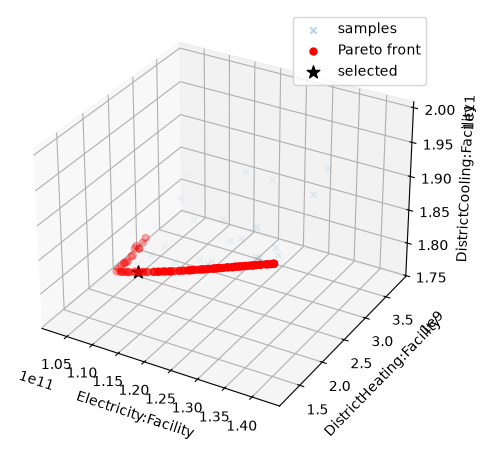

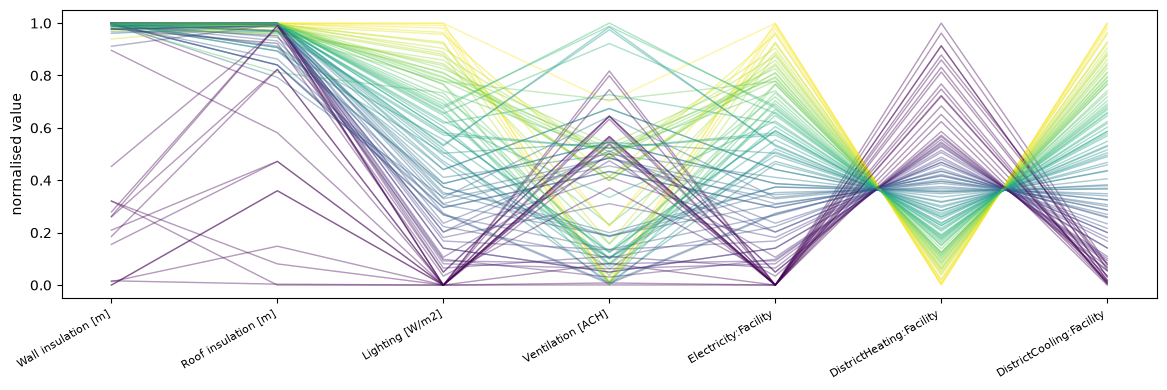

In [15]:
viz.pareto(front, background=data, highlight=best)
plt.show()
viz.parallel_coordinates(front.df, problem)
plt.show()

## Check the selected design

The surrogate is approximate, and optimizers like to find the places where it is wrong. Simulate the selected
design with EnergyPlus and compare.

In [16]:
x = best[problem.parameter_names].to_frame().T.reset_index(drop=True)
comparison = pd.DataFrame({"EnergyPlus": evaluator.evaluate(x).iloc[0], "surrogate": surrogate.predict(x).iloc[0]})
comparison["difference [%]"] = 100 * (comparison["surrogate"] - comparison["EnergyPlus"]) / comparison["EnergyPlus"]
comparison

,EnergyPlus,surrogate,difference [%]
Electricity:Facility,1.0953e+11,1.0953e+11,2.9560e-05
DistrictHeating:Facility,2.1014e+09,2.0570e+09,-2.1119e+00
DistrictCooling:Facility,1.7909e+11,1.7930e+11,1.1561e-01


If the difference is larger than you can accept, add this design to the training data
(`initial_data=` of {meth}`~bdopt.adaptive.AdaptiveSampler.run`) or simply spend more simulations and optimize
again. The same study written as a configuration file is in {doc}`../guide/studies`.